# Correlation function multipoles

The redshift-space correlation function multipoles of a galaxy sample, and their derivatives with respect to the cosmological parameters.

Galaxy surveys measure clustering in redshift space, where peculiar velocities squash structures along the line of sight. In linear theory (Kaiser) a tracer of bias $b$ has the power spectrum multipoles

$$
P_0 = \left(1 + \tfrac{2}{3} \beta + \tfrac{1}{5} \beta^2\right) b^2 P, \qquad
P_2 = \left(\tfrac{4}{3} \beta + \tfrac{4}{7} \beta^2\right) b^2 P, \qquad
P_4 = \tfrac{8}{35} \beta^2 b^2 P,
$$

with $\beta = f / b$ and $f = \mathrm{d} \ln \delta / \mathrm{d} \ln a$ the growth rate. The correlation function multipoles are their Hankel transforms,

$$
\xi_\ell(s) = \frac{i^\ell}{2 \pi^2} \int \mathrm{d}k \, k^2 P_\ell(k) \, j_\ell(k s) .
$$

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import LCDM, solve_eb

REDSHIFT = 0.5
BIAS = 2.0
SMOOTHING = 1.0  # Gaussian damping of P(k), Mpc: makes the transform converge
K = np.geomspace(1.0e-4, 4.0, 192)  # wave numbers of the solve, 1/Mpc
K_FINE = np.geomspace(K[0], K[-1], 8192)  # of the transform: resolves j_l(k s)
S = np.linspace(20.0, 200.0, 91)  # separations, Mpc

## The cosmology and its parameters

The Planck 2018 best fit, differentiated in $H_0$, $\Omega_m$, $\Omega_b$ and $n_s$. `from_density_parameters` turns these into the model's physical densities, in JAX, so the derivatives go through it.

In [2]:
h = 0.6732117
PLANCK = dict(
    Omegam=(0.02238280 + 0.1201075) / h**2,
    Omegab=0.02238280 / h**2,
    H0=100.0 * h,
    A_s=2.100549e-9,
    n_s=0.9660499,
    Tcmb=2.7255,
    YHe=0.2454006,
    Neff=3.046,
)
PARAMETERS = {"H0": "H_0", "Omegam": r"\Omega_m", "Omegab": r"\Omega_b", "n_s": "n_s"}
theta = jnp.asarray([PLANCK[key] for key in PARAMETERS])

## The save point

`solve_eb` integrates in the scale factor and differentiates at fixed scale factor. The sample's redshift is the one save point, and every derivative below is at that redshift.

In [3]:
A_SAMPLE = 1.0 / (1.0 + REDSHIFT)

## Spherical Bessel functions

The transform needs $j_0$, $j_2$ and $j_4$. Their closed forms cancel badly at small arguments, so a series takes over below $x = 1/2$.

In [4]:
def spherical_bessel(ell, x):
    """``j_l(x)`` for ``l`` of 0, 2 or 4: the closed form, and its series below 1/2."""

    big = jnp.maximum(x, 0.5)
    sin, cos = jnp.sin(big), jnp.cos(big)
    if ell == 0:
        closed, lead = sin / big, 1.0
    elif ell == 2:
        closed = (3.0 / big**3 - 1.0 / big) * sin - 3.0 / big**2 * cos
        lead = x**2 / 15.0
    else:
        closed = (105.0 / big**5 - 45.0 / big**3 + 1.0 / big) * sin
        closed -= (105.0 / big**4 - 10.0 / big**2) * cos
        lead = x**4 / 945.0
    n = 2 * ell + 3
    series = lead * (1.0 - x**2 / (2 * n) + x**4 / (8 * n * (n + 2)))
    return jnp.where(x < 0.5, series, closed)

## The multipoles

`solve_eb` keeps the density contrasts, the metric perturbation `z`, the baryon velocity `vb` and the expansion rate `adotoa`. In the synchronous gauge $\delta_c' = -k z$ and $\delta_b' = -k (z + v_b)$, so the growth rate is

$$
f = \frac{\delta'}{a H \, \delta} = -\frac{k \, (z + f_b v_b)}{a H \, \delta},
$$

with $f_b = \omega_b / (\omega_c + \omega_b)$. The Hankel transform is a trapezoid rule in $\ln k$ on a fine grid, with a Gaussian damping of $P(k)$ to make it converge.

In [5]:
def multipoles(theta):
    """``xi_0, xi_2, xi_4`` at the separations ``S``, ``(3, len(S))``."""

    cosmology = LCDM.from_density_parameters(
        **{**PLANCK, **dict(zip(PARAMETERS, theta))}
    )
    values = solve_eb(
        cosmology, K, [A_SAMPLE], keep=("clxc", "clxb", "z", "vb", "adotoa")
    )
    clxc, clxb, z, vb, adotoa = values[0, :, :, 0]  # each (k,), at the redshift

    f_b = cosmology.omega_b / (cosmology.omega_c + cosmology.omega_b)
    delta = (1.0 - f_b) * clxc + f_b * clxb
    growth_rate = -K * (z + f_b * vb) / (adotoa * delta)
    primordial = cosmology.A_s * (K / cosmology.k_p) ** (cosmology.n_s - 1.0)
    pk = 2.0 * jnp.pi**2 / K**3 * primordial * delta**2

    beta = growth_rate / BIAS
    kaiser = (
        1.0 + 2.0 / 3.0 * beta + beta**2 / 5.0,
        4.0 / 3.0 * beta + 4.0 / 7.0 * beta**2,
        8.0 / 35.0 * beta**2,
    )
    xi = []
    for ell, sign, factor in zip((0, 2, 4), (1.0, -1.0, 1.0), kaiser):
        log_p = jnp.interp(np.log(K_FINE), np.log(K), jnp.log(BIAS**2 * factor * pk))
        integrand = K_FINE**3 * jnp.exp(log_p - (K_FINE * SMOOTHING) ** 2)
        bessel = spherical_bessel(ell, K_FINE * S[:, None])
        integral = jnp.trapezoid(integrand * bessel, np.log(K_FINE), axis=-1)
        xi.append(sign * integral / (2.0 * jnp.pi**2))
    return jnp.stack(xi)

## The multipoles and their derivatives

One solve for the multipoles, and one forward-sensitivity launch for their derivatives with respect to all four parameters.

In [6]:
xi = np.asarray(multipoles(theta))
dxi = np.asarray(jax.jacfwd(multipoles)(theta))  # (multipole, s, parameter)

In [7]:
print(f"z = {REDSHIFT}, b = {BIAS}")
print(f"{'s [Mpc]':>8}  {'s^2 xi_0':>10}  {'s^2 xi_2':>10}  {'s^2 xi_4':>10}")
for i in range(0, len(S), 10):
    print(f"{S[i]:8.0f}" + "".join(f"  {v:10.3f}" for v in S[i] ** 2 * xi[:, i]))
peak = (S > 120.0) & (S < 180.0)
print(f"BAO peak of xi_0 at s = {S[peak][np.argmax(xi[0, peak])]:.0f} Mpc")

z = 0.5, b = 2.0
 s [Mpc]    s^2 xi_0    s^2 xi_2    s^2 xi_4
      20     256.207    -123.179       5.416
      40     230.875    -186.993      10.134
      60     172.095    -209.024      12.958
      80     118.536    -211.438      14.542
     100      74.800    -204.816      15.330
     120      37.558    -194.829      15.603
     140      79.874    -153.964      16.707
     160      89.410    -143.755      14.927
     180      -3.359    -171.948      12.771
     200     -40.698    -168.495      12.989
BAO peak of xi_0 at s = 148 Mpc


The derivatives show, for instance, how the BAO peak shifts with the Hubble constant.

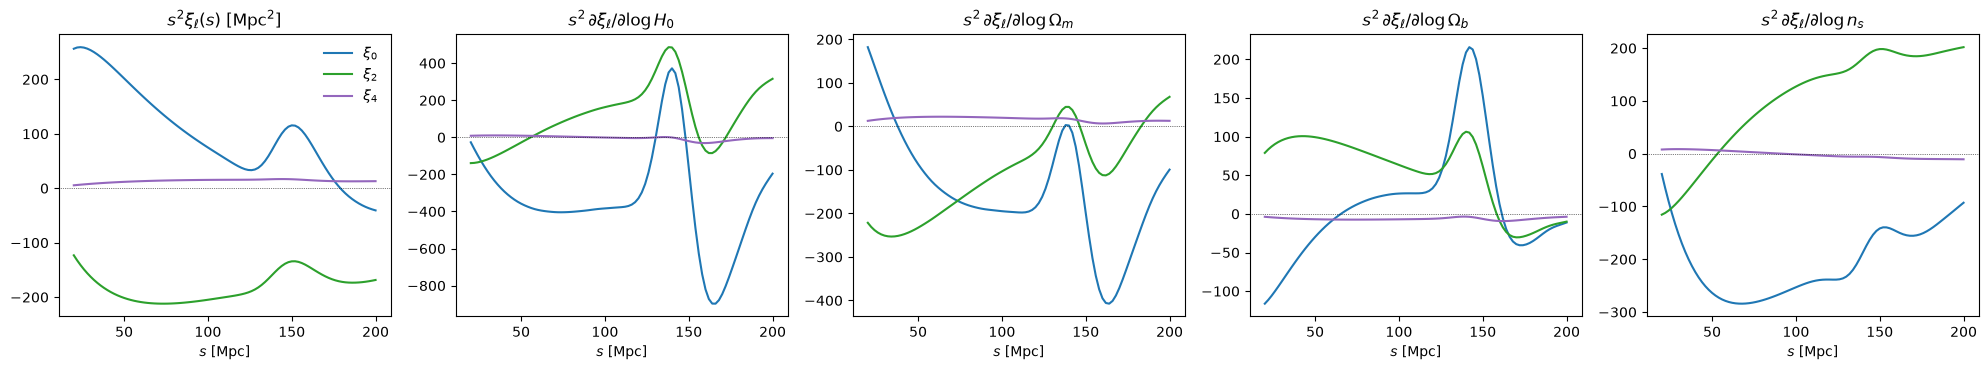

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8), sharex=True)
styles = (("C0", r"$\xi_0$"), ("C2", r"$\xi_2$"), ("C4", r"$\xi_4$"))
for ell, (color, label) in enumerate(styles):
    axes[0].plot(S, S**2 * xi[ell], color=color, label=label)
    for i, ax in enumerate(axes[1:]):
        ax.plot(S, S**2 * theta[i] * dxi[ell, :, i], color=color)
axes[0].set_title(r"$s^2 \xi_\ell(s)$ [Mpc$^2$]")
axes[0].legend(frameon=False)
for ax, label in zip(axes[1:], PARAMETERS.values()):
    ax.set_title(rf"$s^2\, \partial \xi_\ell / \partial \log {label}$")
for ax in axes:
    ax.axhline(0.0, color="k", lw=0.5, ls=":")
    ax.set_xlabel(r"$s$ [Mpc]")
fig.tight_layout()
plt.show()